# POD + non-intrusive regression ROM — `impesFoam2ph` 5-spot

Based on `inj_prod.ipynb`, with baseline `impesFoam3ph/Examples/2ph_Well/5spot_panday`.

The parameters are $\boldsymbol{\theta}=(q_{\rm inj},\mu_a,\mu_b)$:
- `constant/wellProperties/ConstantInjection/wells/injector1/target = q_inj`;
- `constant/wellProperties/ConstantInjection/wells/producer1/target = -q_inj`;
- `mu_a` (oil) and `mu_b` (water) in `constant/transportProperties`, in Pa.s.

Pipeline:
$
\boldsymbol{\theta}\to\text{FOM runs}\to S_b(\mathbf x,t;\boldsymbol{\theta})\to
\text{POD}\to a(t,\boldsymbol{\theta})\to\text{regression}\to\hat a(t,\boldsymbol{\theta})\to\hat S_b.
$

The notebook separates **POD projection error**, **regression error**, and **total ROM error**. The train/validation/test split is by complete parameter trajectories, avoiding leakage between times of the same simulation.

Requirements: OpenFOAM.org v9, compiled `impesFoam2ph`, `fluidfoam`, `pymor`, `numpy`, `pandas`, `scipy`, `scikit-learn`, `matplotlib`, `joblib`.

All changes are applied to copied cases. The baseline remains unchanged, and results are stored separately in `rom_5spot_qinj_mu`.


In [2]:
# Uncomment if Python dependencies are missing:
# %pip install numpy pandas scipy matplotlib scikit-learn fluidfoam pymor joblib

In [3]:
from pathlib import Path
import os, re, shutil, subprocess, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import Ridge
from sklearn.kernel_ridge import KernelRidge
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import r2_score, mean_squared_error

from pymor.vectorarrays.numpy import NumpyVectorSpace
from pymor.algorithms.pod import pod
import fluidfoam

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

## 1. Configuration

In [4]:
REPO_DIR = Path.cwd().parents[1]  # Run from impesFoam3ph/Examples/test
print(REPO_DIR)
# REPO_URL = "https://github.com/UnderMou/impesFoam3ph.git"
BASE_CASE = REPO_DIR / "Examples/2ph_Well/5spot_panday"

SOLVER = "impesFoam2ph"
FIELD = "Sb"
FOAM_BASHRC = None  # e.g. "/opt/openfoam9/etc/bashrc" if needed

N_CASES = 200  # Total parameter combinations, not a Cartesian product
Q_FACTOR_MIN, Q_FACTOR_MAX = 0.50, 1.50
MU_A_FACTOR_MIN, MU_A_FACTOR_MAX = 0.50, 1.50
MU_B_FACTOR_MIN, MU_B_FACTOR_MAX = 0.50, 1.50
SAMPLING = "lhs"   # Options: "linspace", "random", "lhs"

CENTER_SNAPSHOTS = True
POD_ENERGY = 0.9999
MAX_POD_MODES = None

TRAIN_FRACTION = 0.67
VAL_FRACTION = 0.13

WORK_DIR = Path.cwd() / "rom_5spot_qinj_mu"
CASES_DIR = WORK_DIR / "cases"
ARTIFACTS_DIR = WORK_DIR / "artifacts"
CASES_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

if not BASE_CASE.exists():
    print("Baseline absent; cloning public repository...")
    REPO_DIR.parent.mkdir(parents=True, exist_ok=True)
    # subprocess.run(["git", "clone", REPO_URL, str(REPO_DIR)], check=True)

assert BASE_CASE.exists(), f"Case not found: {BASE_CASE}"
print(BASE_CASE)

/home/anderson/OpenFOAM/anderson-9/run/struct_impesFoam/impesFoam3ph_v6/impesFoam3ph
/home/anderson/OpenFOAM/anderson-9/run/struct_impesFoam/impesFoam3ph_v6/impesFoam3ph/Examples/2ph_Well/5spot_panday


## 2. Read/change well targets and viscosities

The well parser descends through `ConstantInjection → wells → injector1/producer1`. The viscosity parser replaces only the numerical values of `mu_a` and `mu_b`, preserving dimension vectors, comments, and all other transport properties. The values used for sampling are read from `BASE_CASE`.


In [5]:
def find_named_block(text, name, start=0):
    m = re.search(rf"\b{re.escape(name)}\b\s*\{{", text[start:])
    if not m:
        raise ValueError(f"Block {name!r} not found")
    op = start + m.end() - 1
    depth = 0
    for i in range(op, len(text)):
        if text[i] == "{":
            depth += 1
        elif text[i] == "}":
            depth -= 1
            if depth == 0:
                return op, i
    raise ValueError(f"Unclosed block {name!r}")

def well_span(text, well_name):
    """
    Locate:
    ConstantInjection
      -> wells
         -> <well_name>
    """
    lo, hi = find_named_block(text, "ConstantInjection")
    lo, hi = find_named_block(text, "wells", lo + 1)
    lo, hi = find_named_block(text, well_name, lo + 1)
    return lo, hi

def read_target(path, well_name):
    """Read target from a specific well."""
    text = Path(path).read_text()
    lo, hi = well_span(text, well_name)
    block = text[lo:hi+1]

    m = re.search(
        r"\btarget\s+([+\-0-9.eE]+)\s*;",
        block
    )
    if not m:
        raise ValueError(f"target not found for well {well_name!r}")

    return float(m.group(1))

def set_target(path, well_name, q):
    """Set and verify target for a specific well."""
    p = Path(path)
    text = p.read_text()

    lo, hi = well_span(text, well_name)
    block = text[lo:hi+1]

    block2, n = re.subn(
        r"(\btarget\s+)([+\-0-9.eE]+)(\s*;)",
        rf"\g<1>{q:.16g}\g<3>",
        block,
        count=1
    )

    if n != 1:
        raise ValueError(
            f"Could not replace target for well {well_name!r}"
        )

    p.write_text(text[:lo] + block2 + text[hi+1:])

    q_read = read_target(p, well_name)

    if not np.isclose(q_read, q, rtol=1e-12, atol=0.0):
        raise RuntimeError(
            f"Failed setting {well_name}: "
            f"requested={q}, read={q_read}"
        )


def viscosity_pattern(name):
    if name not in ("mu_a", "mu_b"):
        raise ValueError(f"Unsupported viscosity: {name!r}")
    key = re.escape(name)
    number = r"[+-]?(?:\d+(?:\.\d*)?|\.\d+)(?:[eE][+-]?\d+)?"
    # Accept: mu_a mu_a [dimensions] value; mu_a [dimensions] value;
    # or mu_a value;. Anchoring excludes // commented-out entries.
    return re.compile(
        rf"^([ \t]*{key}[ \t]+(?:{key}[ \t]+)?"
        rf"(?:\[[^\]\r\n]*\][ \t]*)?)({number})([ \t]*;)",
        re.MULTILINE,
    )


def read_viscosity(path, name):
    matches = list(viscosity_pattern(name).finditer(Path(path).read_text()))
    if len(matches) != 1:
        raise ValueError(f"Expected one {name!r} entry in {path}; found {len(matches)}")
    value = float(matches[0].group(2))
    if not np.isfinite(value) or value <= 0:
        raise ValueError(f"{name} must be finite and positive; got {value}")
    return value


def set_viscosity(path, name, value):
    value = float(value)
    if not np.isfinite(value) or value <= 0:
        raise ValueError(f"{name} must be finite and positive; got {value}")
    p = Path(path)
    text = p.read_text()
    read_viscosity(p, name)  # Reject missing, ambiguous, or invalid entries.
    updated, count = viscosity_pattern(name).subn(
        lambda m: f"{m.group(1)}{value:.16g}{m.group(3)}", text
    )
    if count != 1:
        raise ValueError(f"Could not replace {name!r} in {path}")
    p.write_text(updated)
    actual = read_viscosity(p, name)
    if not np.isclose(actual, value, rtol=1e-12, atol=0.0):
        raise RuntimeError(f"Failed setting {name}: requested={value}, read={actual}")

WELL_FILE = BASE_CASE / "constant/wellProperties"

q0 = read_target(WELL_FILE, "injector1")
qprod0 = read_target(WELL_FILE, "producer1")

print(f"Baseline injector target = {q0:.12e}")
print(f"Baseline producer target = {qprod0:.12e}")
TRANSPORT_FILE = BASE_CASE / "constant/transportProperties"
mu_a0 = read_viscosity(TRANSPORT_FILE, "mu_a")
mu_b0 = read_viscosity(TRANSPORT_FILE, "mu_b")
if not np.isfinite(q0) or q0 <= 0:
    raise ValueError("Baseline injector target must be finite and positive")
print(f"Baseline mu_a = {mu_a0:.12e} Pa.s")
print(f"Baseline mu_b = {mu_b0:.12e} Pa.s")


Baseline injector target = 2.479068205754e-04
Baseline producer target = -2.479068205754e-04
Baseline mu_a = 2.170000000000e-03 Pa.s
Baseline mu_b = 5.000000000000e-04 Pa.s


## 3. Sample $(q_{\rm inj},\mu_a,\mu_b)$ and split by complete simulations

`N_CASES` is the total number of simulations (default: 60). Each parameter has its own configurable factor range relative to its baseline value (default: 0.50–1.50).

With `SAMPLING="linspace"`, injection levels are evenly spaced as in the original notebook, while the two viscosity level arrays are independently shuffled. This avoids varying all three parameters along a single diagonal. With `SAMPLING="random"`, the three factors are independently sampled from uniform distributions. With `SAMPLING="lhs"`, Latin Hypercube Sampling places one sample in each of `N_CASES` equal strata per parameter and scales the samples to their respective factor ranges. Sampling uses the seeded `rng` for reproducibility. None of these options constructs a Cartesian product.

A complete parameter combination belongs to a single train/validation/test split.


In [6]:
if N_CASES < 4:
    raise ValueError("N_CASES must be at least 4 for train/validation/test splits")
if not (0 < TRAIN_FRACTION < 1 and 0 < VAL_FRACTION < 1
        and TRAIN_FRACTION + VAL_FRACTION < 1):
    raise ValueError("Invalid train/validation fractions")
for name, low, high in [
    ("q_inj", Q_FACTOR_MIN, Q_FACTOR_MAX),
    ("mu_a", MU_A_FACTOR_MIN, MU_A_FACTOR_MAX),
    ("mu_b", MU_B_FACTOR_MIN, MU_B_FACTOR_MAX),
]:
    if not (np.isfinite(low) and np.isfinite(high) and 0 < low < high):
        raise ValueError(f"Invalid factor range for {name}: {low}, {high}")

if SAMPLING == "linspace":
    factors = np.linspace(Q_FACTOR_MIN, Q_FACTOR_MAX, N_CASES)
    mu_a_factors = rng.permutation(np.linspace(MU_A_FACTOR_MIN, MU_A_FACTOR_MAX, N_CASES))
    mu_b_factors = rng.permutation(np.linspace(MU_B_FACTOR_MIN, MU_B_FACTOR_MAX, N_CASES))
elif SAMPLING == "random":
    factors = np.sort(rng.uniform(Q_FACTOR_MIN, Q_FACTOR_MAX, N_CASES))
    mu_a_factors = rng.uniform(MU_A_FACTOR_MIN, MU_A_FACTOR_MAX, N_CASES)
    mu_b_factors = rng.uniform(MU_B_FACTOR_MIN, MU_B_FACTOR_MAX, N_CASES)
elif SAMPLING == "lhs":
    from scipy.stats import qmc

    # One sample in each of N_CASES strata per parameter.
    unit_samples = qmc.LatinHypercube(d=3, seed=rng).random(n=N_CASES)
    factor_samples = qmc.scale(
        unit_samples,
        [Q_FACTOR_MIN, MU_A_FACTOR_MIN, MU_B_FACTOR_MIN],
        [Q_FACTOR_MAX, MU_A_FACTOR_MAX, MU_B_FACTOR_MAX],
    )
    # Sort complete parameter tuples to preserve their LHS pairing.
    factor_samples = factor_samples[np.argsort(factor_samples[:, 0])]
    factors, mu_a_factors, mu_b_factors = factor_samples.T
else:
    raise ValueError(f"Unknown SAMPLING: {SAMPLING!r}")
q_values = q0 * factors
mu_a_values = mu_a0 * mu_a_factors
mu_b_values = mu_b0 * mu_b_factors

idx = np.arange(N_CASES); rng.shuffle(idx)
ntr = max(2, int(round(TRAIN_FRACTION*N_CASES)))
nva = min(max(1, int(round(VAL_FRACTION*N_CASES))), N_CASES-3)
if N_CASES-ntr-nva < 1: ntr = N_CASES-nva-1
split = {}
for i in idx[:ntr]: split[i] = "train"
for i in idx[ntr:ntr+nva]: split[i] = "val"
for i in idx[ntr+nva:]: split[i] = "test"

sampling_df = pd.DataFrame({
    "case_id": np.arange(N_CASES), "q_inj": q_values,
    "mu_a": mu_a_values, "mu_b": mu_b_values,
    "factor_q0": factors, "factor_mu_a0": mu_a_factors,
    "factor_mu_b0": mu_b_factors,
    "split": [split[i] for i in range(N_CASES)]
})
display(sampling_df.sort_values("q_inj"))


,case_id,q_inj,mu_a,mu_b,factor_q0,factor_mu_a0,factor_mu_b0,split
0,0,0.000125,0.003000,0.000416,0.504399,1.382569,0.831240,train
1,1,0.000125,0.002992,0.000670,0.505533,1.378728,1.340816,val
2,2,0.000127,0.002257,0.000407,0.513453,1.040227,0.814125,train
3,3,0.000128,0.002662,0.000518,0.515576,1.226792,1.035921,train
4,4,0.000130,0.002813,0.000699,0.523773,1.296218,1.397521,train
...,...,...,...,...,...,...,...,...
195,195,0.000366,0.003213,0.000271,1.475614,1.480781,0.541535,train
196,196,0.000367,0.002721,0.000601,1.480723,1.254122,1.202909,train
197,197,0.000368,0.003211,0.000540,1.485824,1.479549,1.080096,train
198,198,0.000370,0.002030,0.000632,1.490609,0.935356,1.263265,train


### Pairwise sample plots

Each point represents a complete sampled case. Colors identify the train, validation, and test splits.


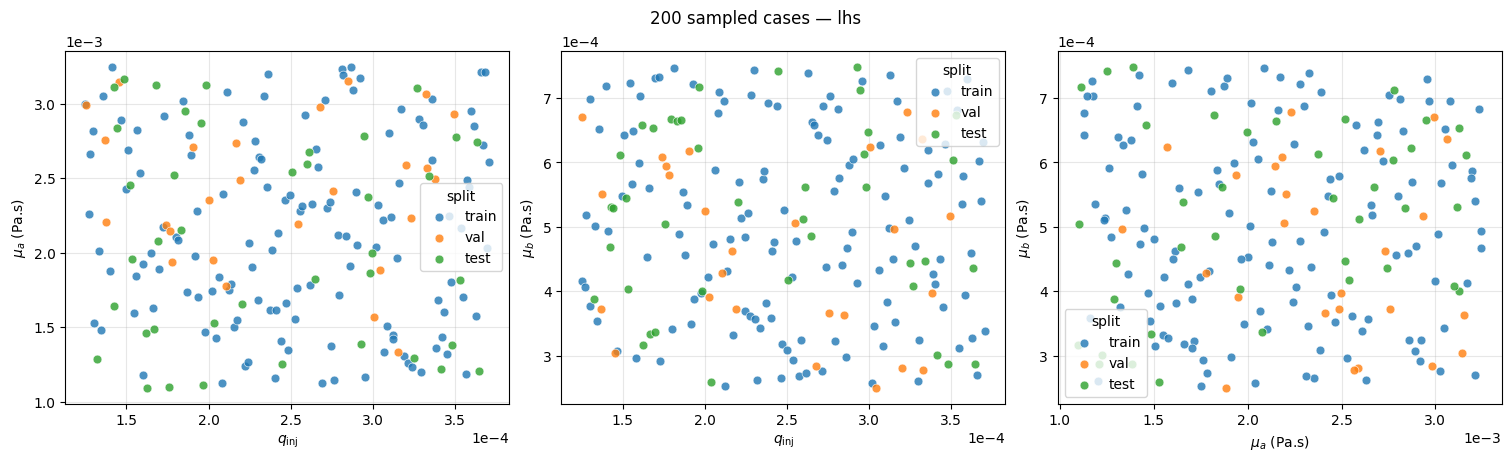

In [7]:
parameter_pairs = [("q_inj", "mu_a"), ("q_inj", "mu_b"), ("mu_a", "mu_b")]
parameter_labels = {
    "q_inj": r"$q_{\mathrm{inj}}$",
    "mu_a": r"$\mu_a$ (Pa.s)",
    "mu_b": r"$\mu_b$ (Pa.s)",
}
split_colors = {"train": "tab:blue", "val": "tab:orange", "test": "tab:green"}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)
for ax, (x_parameter, y_parameter) in zip(axes, parameter_pairs):
    for split_name, color in split_colors.items():
        subset = sampling_df.loc[sampling_df["split"].eq(split_name)]
        ax.scatter(
            subset[x_parameter], subset[y_parameter],
            color=color, label=split_name, s=40, alpha=0.8,
            edgecolors="white", linewidths=0.5,
        )
    ax.set_xlabel(parameter_labels[x_parameter])
    ax.set_ylabel(parameter_labels[y_parameter])
    ax.ticklabel_format(style="sci", axis="both", scilimits=(0, 0))
    ax.grid(alpha=0.3)
    ax.set_axisbelow(True)
    ax.legend(title="split")

fig.suptitle(f"{len(sampling_df)} sampled cases — {SAMPLING}")
plt.show()


## 4. Generate and run OpenFOAM cases

Set `RUN_FOM=False` after the database has been generated if you only want to rebuild/retrain the ROM.

In [8]:
from concurrent.futures import ProcessPoolExecutor, as_completed

NP = 15
N_PARALLEL = max(1, min(NP, os.cpu_count() or 1))

print(os.cpu_count())
print(f"Running {N_CASES} cases with {N_PARALLEL} parallel workers")


def is_time_dir(p):
    if not p.is_dir(): return False
    try: float(p.name); return True
    except ValueError: return False


def clean_results(case):
    for p in Path(case).iterdir():
        if is_time_dir(p) and float(p.name) > 0: shutil.rmtree(p)
        elif p.is_dir() and p.name.startswith("processor"): shutil.rmtree(p)
    for p in Path(case).glob("log.*"):
        if p.is_file(): p.unlink()


def run_shell(cmd, cwd, logfile):
    cmd = f"source {FOAM_BASHRC} && {cmd}" if FOAM_BASHRC else cmd
    with open(Path(cwd)/logfile, "w") as f:
        r = subprocess.run(["bash", "-lc", cmd], cwd=cwd,
                           stdout=f, stderr=subprocess.STDOUT, text=True)
    if r.returncode:
        raise RuntimeError(f"Failed: {cmd}; inspect {Path(cwd)/logfile}")


def prepare_case(i, q, mu_a, mu_b):
    dst = CASES_DIR / f"q_{i:03d}"

    if dst.exists():
        shutil.rmtree(dst)

    # Create a fresh copy. BASE_CASE is never modified.
    shutil.copytree(BASE_CASE, dst)
    clean_results(dst)

    well_file = dst / "constant/wellProperties"

    # Use the same sampled target for injector and producer.
    set_target(well_file, "injector1", q)
    set_target(well_file, "producer1", -q)

    transport_file = dst / "constant/transportProperties"
    set_viscosity(transport_file, "mu_a", mu_a)
    set_viscosity(transport_file, "mu_b", mu_b)

    # Explicit sanity check before running OpenFOAM.
    q_inj_read = read_target(well_file, "injector1")
    q_prod_read = read_target(well_file, "producer1")

    print(
        f"case={i:03d} | q_inj={q:.6e} | q_prod_expected={-q:.6e} | "
        f"injector={q_inj_read:.6e} | "
        f"producer={q_prod_read:.6e} | "
        f"mu_a={read_viscosity(transport_file, 'mu_a'):.6e} | "
        f"mu_b={read_viscosity(transport_file, 'mu_b'):.6e}"
    )

    return dst


def run_case(case):
    run_shell("blockMesh", case, "log.blockMesh")
    run_shell(SOLVER, case, f"log.{SOLVER}")


def run_one_case(case_id, q_inj, mu_a, mu_b, split):
    case = prepare_case(case_id, q_inj, mu_a, mu_b)
    print(f"[{case_id:03d}] q={q_inj:.6e} mu_a={mu_a:.6e} mu_b={mu_b:.6e} {split}")
    tic = time.perf_counter()
    run_case(case)
    dt = time.perf_counter() - tic
    print(f"  {dt:.1f} s")
    return (case_id, q_inj, mu_a, mu_b, split, dt)


RUN_FOM = False
records = []
if RUN_FOM:
    rows = [(int(r.case_id), float(r.q_inj), float(r.mu_a), float(r.mu_b), str(r.split))
            for r in sampling_df.itertuples()]

    if N_PARALLEL > 1:
        with ProcessPoolExecutor(max_workers=N_PARALLEL) as executor:
            futures = [executor.submit(run_one_case, *row) for row in rows]
            for fut in as_completed(futures):
                records.append(fut.result())
    else:
        for row in rows:
            records.append(run_one_case(*row))

    timings_df = pd.DataFrame(
        records,
        columns=["case_id", "q_inj", "mu_a", "mu_b", "split", "wall_time_s"]
    )
    display(timings_df)

12
Running 200 cases with 12 parallel workers


## 5. Read common output times and `Sb` snapshots with `fluidfoam`

In [9]:
N_CELLS = 2601

def available_times(case):
    out={}
    for p in Path(case).iterdir():
        if is_time_dir(p): out[float(p.name)] = p.name
    return dict(sorted(out.items()))

maps=[available_times(CASES_DIR/f"q_{i:03d}") for i in range(N_CASES)]
common=sorted(set.intersection(*[set(x) for x in maps]))
if not common: raise RuntimeError("No common output times")
times=np.asarray(common)
time_names=[maps[0][t] for t in common]
print(len(times), "common times:", times[:4], "...", times[-4:])

# def read_scalar(case,tname,field=FIELD):
#     return np.asarray(fluidfoam.readscalar(str(case),str(tname),field),
#                       dtype=float).squeeze().ravel()
def read_scalar(case, tname, field=FIELD):

    u = np.asarray(
        fluidfoam.readscalar(
            str(case),
            str(tname),
            field
        ),
        dtype=float
    ).squeeze().ravel()

    # OpenFOAM "internalField uniform ..."
    if u.size == 1:
        u = np.full(N_CELLS, u.item())

    if u.size != N_CELLS:
        raise ValueError(
            f"Unexpected field size in "
            f"case={case}, time={tname}, field={field}: "
            f"got {u.size}, expected {N_CELLS}"
        )

    return u

snaps=[]; rows=[]
for row in sampling_df.itertuples():
    case=CASES_DIR/f"q_{row.case_id:03d}"
    for t,tname in zip(times,time_names):
        snaps.append(read_scalar(case,tname))
        rows.append(dict(case_id=row.case_id,q_inj=row.q_inj,
                         mu_a=row.mu_a,mu_b=row.mu_b,t=t,split=row.split))

for i, (s, row) in enumerate(zip(snaps, rows)):
    print(
        i,
        "case =", row["case_id"],
        "t =", row["t"],
        "shape =", np.asarray(s).shape
    )


X=np.vstack(snaps)
meta=pd.DataFrame(rows)
print("X:",X.shape,"(snapshots, cells)")
display(meta.groupby("split").size())

51 common times: [       0. 10000000. 20000000. 30000000.] ... [4.7e+08 4.8e+08 4.9e+08 5.0e+08]
Reading file /home/anderson/OpenFOAM/anderson-9/run/struct_impesFoam/impesFoam3ph_v6/impesFoam3ph/Examples/test/rom_5spot_qinj_mu/cases/q_000/0/Sb

Only constant field in output

Reading file /home/anderson/OpenFOAM/anderson-9/run/struct_impesFoam/impesFoam3ph_v6/impesFoam3ph/Examples/test/rom_5spot_qinj_mu/cases/q_000/1e+07/Sb
Reading file /home/anderson/OpenFOAM/anderson-9/run/struct_impesFoam/impesFoam3ph_v6/impesFoam3ph/Examples/test/rom_5spot_qinj_mu/cases/q_000/2e+07/Sb
Reading file /home/anderson/OpenFOAM/anderson-9/run/struct_impesFoam/impesFoam3ph_v6/impesFoam3ph/Examples/test/rom_5spot_qinj_mu/cases/q_000/3e+07/Sb
Reading file /home/anderson/OpenFOAM/anderson-9/run/struct_impesFoam/impesFoam3ph_v6/impesFoam3ph/Examples/test/rom_5spot_qinj_mu/cases/q_000/4e+07/Sb
Reading file /home/anderson/OpenFOAM/anderson-9/run/struct_impesFoam/impesFoam3ph_v6/impesFoam3ph/Examples/test/rom_5spo

split
test     2040
train    6834
val      1326
dtype: int64

## 6. Finite-volume inner product

We use
\[
\langle u,v\rangle_V=u^TM_Vv=\sum_iV_i u_iv_i.
$
The notebook tries `postProcess -func writeCellVolumes`; if unavailable it falls back to equal weights, which is equivalent up to a constant on the uniform rectangular mesh.

In [10]:
def get_volumes(case):
    try:
        run_shell("postProcess -func writeCellVolumes -time 0",case,"log.writeCellVolumes")
        V=read_scalar(case,"0","V")
        if len(V)==X.shape[1] and np.all(V>0): return V
    except Exception as e:
        warnings.warn(str(e))
    warnings.warn("Using equal weights; appropriate up to a constant for uniform mesh.")
    return np.ones(X.shape[1])

V=get_volumes(CASES_DIR/"q_000")
sqrtV=np.sqrt(V)
print("V min/max:",V.min(),V.max(),"uniform:",np.allclose(V,V[0]))

Reading file /home/anderson/OpenFOAM/anderson-9/run/struct_impesFoam/impesFoam3ph_v6/impesFoam3ph/Examples/test/rom_5spot_qinj_mu/cases/q_000/0/V
V min/max: 77.7918 77.7918 uniform: True


## 7. POD from **training cases only**

For centered weighted snapshots
$
y=M_V^{1/2}(u-\bar u),
$
pyMOR computes Euclidean POD modes \(\Psi\). Physical modes are
$
\Phi=M_V^{-1/2}\Psi,\qquad \Phi^TM_V\Phi=I.
$

00:18 pod: Computing SVD ...
00:18 |   method_of_snapshots: Computing Gramian (6834 vectors) ...


X shape    : (10200, 2601)
Ytr shape  : (6834, 2601)
N cells    : 2601
N train    : 6834
pyMOR VectorArray:
len(U) = 6834
dim    = 2601


00:21 |   method_of_snapshots: Computing eigenvalue decomposition ...
01:39 |   method_of_snapshots: Computing left-singular vectors (6834 vectors) ...
01:41 pod: Checking orthonormality ...
01:41 pod: Reorthogonalizing POD modes ...


Psi shape = (2601, 1038)

Selected POD modes
------------------
r      = 67
energy = 0.9999018352897323
orthogonality error = 2.149909871119191e-15


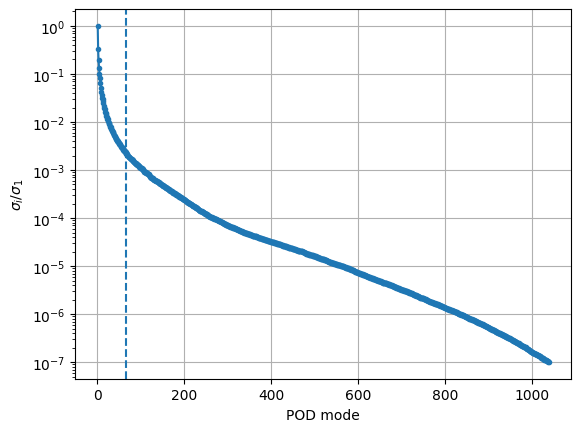

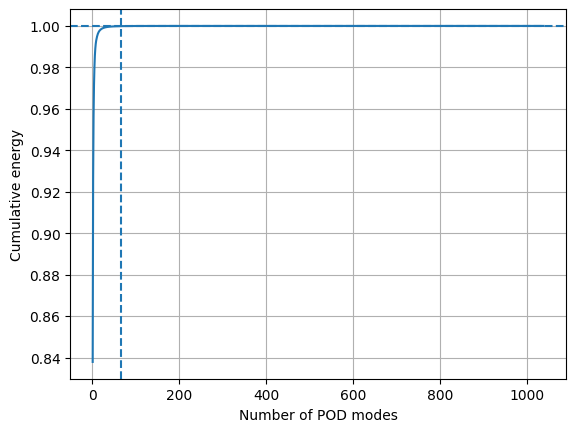

In [11]:
train = meta.split.eq("train").to_numpy()
val   = meta.split.eq("val").to_numpy()
test  = meta.split.eq("test").to_numpy()

# -----------------------------------------
# Mean field using TRAINING snapshots only
# -----------------------------------------
u_mean = (
    X[train].mean(axis=0)
    if CENTER_SNAPSHOTS
    else np.zeros(X.shape[1])
)

# Volume-weighted centered snapshots
#
# Shape:
# Ytr = (N_train_snapshots, N_cells)
#
Ytr = (X[train] - u_mean) * sqrtV[None, :]

print("X shape    :", X.shape)
print("Ytr shape  :", Ytr.shape)
print("N cells    :", X.shape[1])
print("N train    :", train.sum())


# -----------------------------------------
# pyMOR VectorArray
# -----------------------------------------

n_cells = Ytr.shape[1]

space = NumpyVectorSpace(n_cells)

# IMPORTANT:
# this pyMOR version expects:
#
# (vector_dimension, number_of_vectors)
#
# Therefore transpose Ytr.
U = space.from_numpy(Ytr.T)

print("pyMOR VectorArray:")
print("len(U) =", len(U))
print("dim    =", U.dim)


# -----------------------------------------
# POD
# -----------------------------------------

nm = min(Ytr.shape)

if MAX_POD_MODES is not None:
    nm = min(nm, MAX_POD_MODES)

B, svals = pod(
    U,
    modes=nm
)


# -----------------------------------------
# Convert POD basis to NumPy
# -----------------------------------------

# pyMOR returns:
#
# B.to_numpy():
# (N_cells, N_modes)
#
Psi = B.to_numpy()

print("Psi shape =", Psi.shape)


# -----------------------------------------
# POD energy
# -----------------------------------------

energy = (
    np.cumsum(svals**2)
    / np.sum(svals**2)
)

r = int(
    np.searchsorted(
        energy,
        POD_ENERGY
    ) + 1
)

Psi = Psi[:, :r]


# -----------------------------------------
# Return to physical coordinates
# -----------------------------------------

Phi = Psi / sqrtV[:, None]


print()
print("Selected POD modes")
print("------------------")
print("r      =", r)
print("energy =", energy[r-1])


# -----------------------------------------
# Orthogonality check
#
# Phi^T M_V Phi = I
# -----------------------------------------

orth_error = np.linalg.norm(
    Phi.T
    @ (V[:, None] * Phi)
    - np.eye(r)
)

print(
    "orthogonality error =",
    orth_error
)


# -----------------------------------------
# Singular values
# -----------------------------------------

fig, ax = plt.subplots()

ax.semilogy(
    np.arange(1, len(svals)+1),
    svals / svals[0],
    "o-",
    ms=3
)

ax.axvline(
    r,
    ls="--"
)

ax.set(
    xlabel="POD mode",
    ylabel=r"$\sigma_i/\sigma_1$"
)

ax.grid()

plt.show()


# -----------------------------------------
# Cumulative energy
# -----------------------------------------

fig, ax = plt.subplots()

ax.plot(
    np.arange(1, len(energy)+1),
    energy
)

ax.axhline(
    POD_ENERGY,
    ls="--"
)

ax.axvline(
    r,
    ls="--"
)

ax.set(
    xlabel="Number of POD modes",
    ylabel="Cumulative energy"
)

ax.grid()

plt.show()

## 8. Build the target dataset $a(t,\boldsymbol{\theta})$

Since $\Phi^TM_V\Phi=I$,
$
a(t,\boldsymbol{\theta})=\Phi^TM_V[u(t,\boldsymbol{\theta})-\bar u].
$
In weighted coordinates this is simply `A = Y @ Psi`. Each plotted curve is a complete case, colored by its injection rate; its two viscosities remain fixed along the trajectory.


A: (10200, 67)


,case_id,q_inj,mu_a,mu_b,t,split,a1,a2,a3,a4,...,a58,a59,a60,a61,a62,a63,a64,a65,a66,a67
0,0,0.000125,0.003,0.000416,0.0,train,-214.886579,-78.573991,42.092292,-29.024673,...,0.009968,-0.006787,0.002240,0.007116,0.012906,-0.006507,-0.001438,0.005627,0.001307,-0.001858
1,0,0.000125,0.003,0.000416,10000000.0,train,-210.923550,-66.950881,24.949241,-6.380862,...,0.335614,0.398996,-0.105539,-0.001726,-0.415598,-0.247121,-0.504156,-0.153442,-0.398092,0.303722
2,0,0.000125,0.003,0.000416,20000000.0,train,-205.562930,-53.902499,6.931007,13.141938,...,0.086046,0.366155,-0.082739,-0.045375,-0.136861,-0.067385,-0.041460,0.051873,0.080782,-0.110784
3,0,0.000125,0.003,0.000416,30000000.0,train,-198.280429,-37.681332,-11.288605,24.460556,...,0.027428,0.753278,-0.179898,-0.122363,-0.280846,-0.222938,-0.067634,0.211542,0.315121,-0.415694
4,0,0.000125,0.003,0.000416,40000000.0,train,-189.507953,-19.800019,-26.763437,26.105645,...,-0.116718,-0.585242,0.110247,-0.001754,-0.105987,0.338734,-0.054115,-0.336922,-0.394492,0.358387


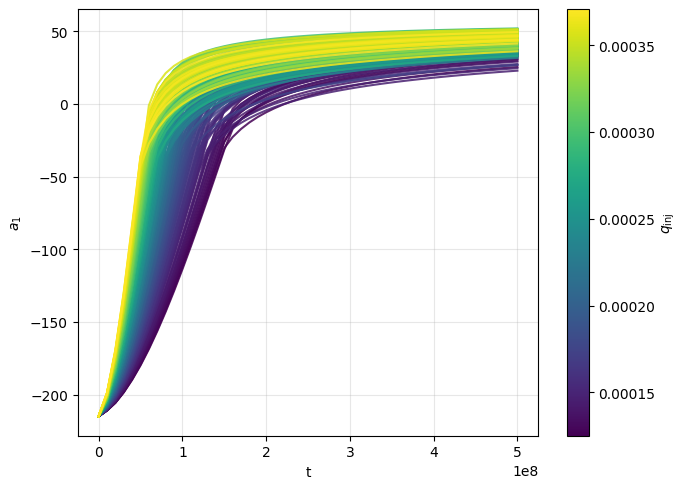

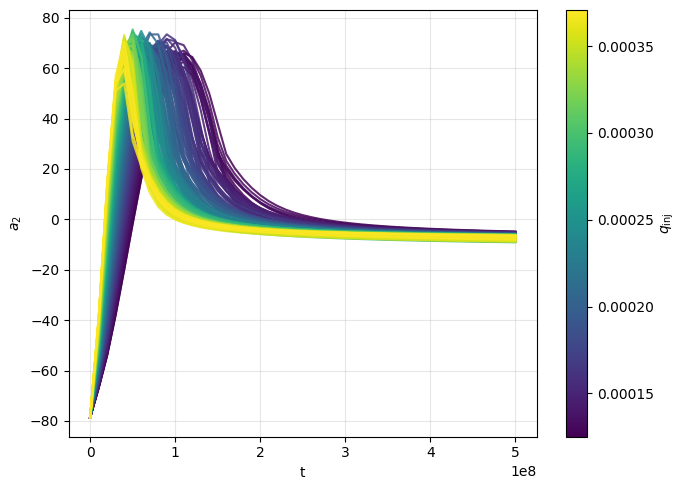

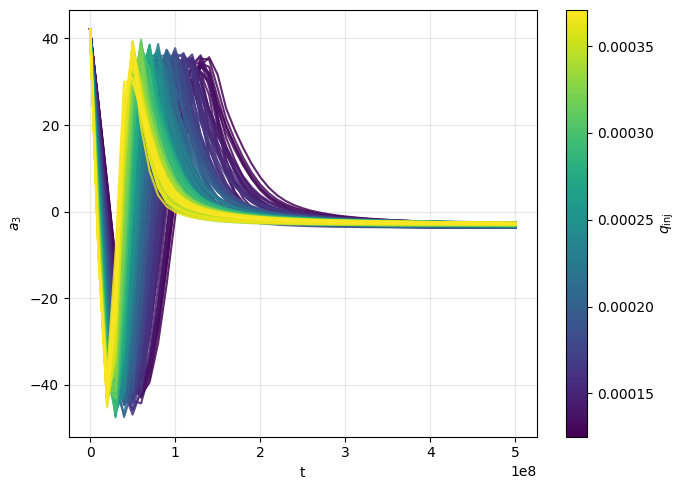

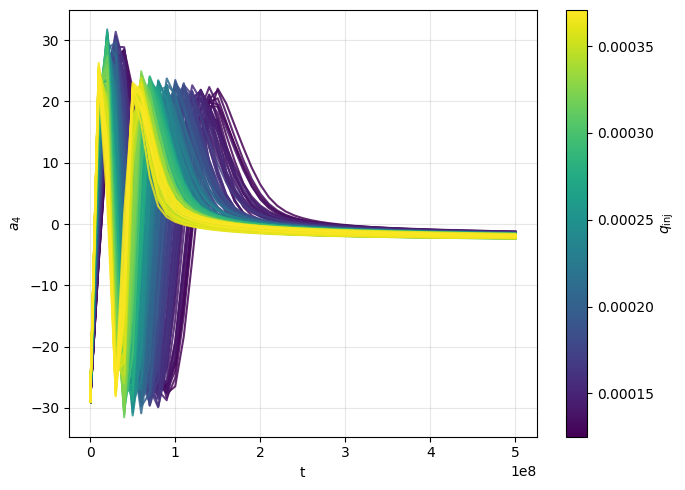

In [12]:
Y=(X-u_mean)*sqrtV[None, :]
A=Y@Psi
print("A:",A.shape)

coef_df=pd.concat([
    meta.reset_index(drop=True),
    pd.DataFrame(A,columns=[f"a{i+1}" for i in range(r)])
],axis=1)
display(coef_df.head())

# for j in range(min(4,r)):
#     fig,ax=plt.subplots()
#     for q in np.sort(meta.q_inj.unique()):
#         m=np.isclose(meta.q_inj,q)
#         ax.plot(meta.loc[m,"t"],A[m,j],alpha=.75)
#     ax.set(xlabel="t",ylabel=fr"$a_{j+1}$"); ax.grid(); plt.show()


import matplotlib.pyplot as plt
import matplotlib as mpl

# Unique q_inj values
q_values = np.sort(meta.q_inj.unique())

# Normalize q_inj for the colormap
norm = mpl.colors.Normalize(
    vmin=q_values.min(),
    vmax=q_values.max()
)

# Choose colormap
cmap = plt.cm.viridis

for j in range(min(4, r)):

    fig, ax = plt.subplots(figsize=(7, 5))

    for case_id, trajectory in meta.groupby("case_id", sort=True):

        m = meta.case_id.eq(case_id).to_numpy()
        q = trajectory.q_inj.iloc[0]

        ax.plot(
            meta.loc[m, "t"],
            A[m, j],
            color=cmap(norm(q)),
            linewidth=1.5,
            alpha=0.85
        )

    ax.set_xlabel("t")
    ax.set_ylabel(fr"$a_{{{j+1}}}$")

    ax.grid(alpha=0.3)

    # ----------------------------------
    # Colorbar representing q_inj
    # ----------------------------------

    sm = mpl.cm.ScalarMappable(
        norm=norm,
        cmap=cmap
    )

    sm.set_array([])

    cbar = fig.colorbar(
        sm,
        ax=ax
    )

    cbar.set_label(
        r"$q_{\mathrm{inj}}$"
    )

    plt.tight_layout()
    plt.show()

## 9. POD projection error — before any regression

In [13]:
def reconstruct(Ap):
    return u_mean[None,:]+Ap@Phi.T

def relL2(Utrue,Upred):
    d=np.sum(V[None,:]*(Utrue-Upred)**2,axis=1)
    n=np.sum(V[None,:]*Utrue**2,axis=1)
    return np.sqrt(d/np.maximum(n,1e-30))

Xpod=reconstruct(A)
poderr=relL2(X,Xpod)
display(pd.DataFrame({"split":meta.split,"POD_relL2":poderr})
        .groupby("split").POD_relL2.agg(["mean","median","max"]))

,mean,median,max
split,,,
test,0.001589,0.000239,0.017536
train,0.001350,0.000203,0.017989
val,0.001477,0.000206,0.022827


## 10. Regression: $(t,q_{\rm inj},\mu_a,\mu_b)\to[a_1,\ldots,a_r]$

We compare Polynomial Ridge, RBF Kernel Ridge, Random Forest, Extra Trees, and MLP. The targets are standardized mode-by-mode because high-order POD coefficients may have much smaller scales.

Time is normalized over the training time range, and each physical parameter is normalized relative to its own baseline value. As in the source notebook's active implementation, each POD coefficient has its own regressor. Section 13 diagnoses each $a_i$.


In [14]:
meta

,case_id,q_inj,mu_a,mu_b,t,split
0,0,0.000125,0.003000,0.000416,0.0,train
1,0,0.000125,0.003000,0.000416,10000000.0,train
2,0,0.000125,0.003000,0.000416,20000000.0,train
3,0,0.000125,0.003000,0.000416,30000000.0,train
4,0,0.000125,0.003000,0.000416,40000000.0,train
...,...,...,...,...,...,...
10195,199,0.000371,0.002608,0.000339,460000000.0,train
10196,199,0.000371,0.002608,0.000339,470000000.0,train
10197,199,0.000371,0.002608,0.000339,480000000.0,train
10198,199,0.000371,0.002608,0.000339,490000000.0,train


In [15]:
tmin,tmax=meta.loc[train,"t"].min(),meta.loc[train,"t"].max()
def features(df):
    tau=(df.t.to_numpy()-tmin)/max(tmax-tmin,1e-30)
    eta=(df.q_inj.to_numpy()-q0)/q0
    eta_mu_a=(df.mu_a.to_numpy()-mu_a0)/mu_a0
    eta_mu_b=(df.mu_b.to_numpy()-mu_b0)/mu_b0
    return np.c_[tau,eta,eta_mu_a,eta_mu_b]
Z=features(meta)

Zm,Am=Z[train],A[train]
Zv,Av=Z[val],A[val]
Zt,At=Z[test],A[test]

Amean=Am.mean(0); Astd=Am.std(0); Astd[Astd<1e-14]=1
scale=lambda x:(x-Amean)/Astd
unscale=lambda x:x*Astd+Amean

# models={
# "Polynomial Ridge d3":make_pipeline(PolynomialFeatures(3,include_bias=False),
#                                     StandardScaler(),Ridge(alpha=1e-6)),
# "Kernel Ridge RBF":make_pipeline(StandardScaler(),
#                                  KernelRidge(alpha=1e-6,kernel="rbf",gamma=2.0)),
# "Random Forest":RandomForestRegressor(n_estimators=400,random_state=42,n_jobs=-1),
# "Extra Trees":ExtraTreesRegressor(n_estimators=400,random_state=42,n_jobs=-1),
# "MLP":make_pipeline(StandardScaler(),
#                     MLPRegressor(hidden_layer_sizes=(64,64),activation="tanh",
#                                  alpha=1e-5,max_iter=5000,early_stopping=True,
#                                  random_state=42))
# }

models={
"Extra Trees":ExtraTreesRegressor(n_estimators=400,random_state=42,n_jobs=-1)
}

In [16]:
from sklearn.base import clone


class SingleOutputEnsemble:
    def __init__(self, models):
        self.models = list(models)

    def predict(self, X):
        preds = [model.predict(X) for model in self.models]
        return np.column_stack(preds)


fitted = {}
out = []

for name, model_template in models.items():
    print("training", name)
    models_per_mode = [clone(model_template) for _ in range(r)]

    for j, model in enumerate(models_per_mode):
        model.fit(Zm, scale(Am)[:, j])

    fitted[name] = SingleOutputEnsemble(models_per_mode)

    for sn, Zs, As, mask in [
        ("train", Zm, Am, train),
        ("val", Zv, Av, val),
        ("test", Zt, At, test),
    ]:
        Ahat = unscale(fitted[name].predict(Zs))
        Uh = reconstruct(Ahat)
        e = relL2(X[mask], Uh)

        out.append(dict(
            model=name,
            split=sn,
            coef_RMSE=np.sqrt(mean_squared_error(As, Ahat)),
            coef_R2=r2_score(As, Ahat, multioutput="variance_weighted"),
            field_relL2_mean=e.mean(),
            field_relL2_median=np.median(e),
            field_relL2_max=e.max(),
            Sb_min_pred=Uh.min(),
            Sb_max_pred=Uh.max(),
        ))

results = pd.DataFrame(out)
display(results.sort_values(["split", "field_relL2_mean"]))

training Extra Trees


,model,split,coef_RMSE,coef_R2,field_relL2_mean,field_relL2_median,field_relL2_max,Sb_min_pred,Sb_max_pred
2,Extra Trees,test,7.009642e-01,0.994849,0.009671,0.002447,0.090216,0.216317,0.958909
0,Extra Trees,train,2.277328e-12,1.000000,0.001350,0.000203,0.017989,0.228345,0.960074
1,Extra Trees,val,5.678181e-01,0.996415,0.007823,0.001693,0.069890,0.242106,0.953424


In [17]:
# # MULTI-OUTPUT REGRESSOR

# fitted={}; out=[]
# for name,model in models.items():
#     print("training",name)
#     model.fit(Zm,scale(Am)); fitted[name]=model
#     for sn,Zs,As,mask in [("train",Zm,Am,train),("val",Zv,Av,val),("test",Zt,At,test)]:
#         Ah=unscale(model.predict(Zs))
#         Uh=reconstruct(Ah); e=relL2(X[mask],Uh)
#         out.append(dict(
#             model=name,split=sn,
#             coef_RMSE=np.sqrt(mean_squared_error(As,Ah)),
#             coef_R2=r2_score(As,Ah,multioutput="variance_weighted"),
#             field_relL2_mean=e.mean(),field_relL2_median=np.median(e),
#             field_relL2_max=e.max(),Sb_min_pred=Uh.min(),Sb_max_pred=Uh.max()))
# results=pd.DataFrame(out)
# display(results.sort_values(["split","field_relL2_mean"]))

## 11. Select by validation performance, then evaluate once on test cases

In [18]:
vr=results[results.split.eq("val")].sort_values("field_relL2_mean")
display(vr)
best_name=vr.iloc[0].model
best=fitted[best_name]
print("Selected:",best_name)

Ahat=unscale(best.predict(Zt))
Xhat=reconstruct(Ahat)
romerr=relL2(X[test],Xhat)

tm=meta.loc[test].reset_index(drop=True).copy()
tm["POD_projection_relL2"]=poderr[test]
tm["ROM_relL2"]=romerr
tm["regression_excess"]=romerr-poderr[test]

display(tm.groupby(["case_id", "q_inj", "mu_a", "mu_b"])[["POD_projection_relL2","ROM_relL2","regression_excess"]]
        .agg(["mean","max"]))
print("mean POD test error:",poderr[test].mean())
print("mean ROM test error:",romerr.mean())
print("max  ROM test error:",romerr.max())

,model,split,coef_RMSE,coef_R2,field_relL2_mean,field_relL2_median,field_relL2_max,Sb_min_pred,Sb_max_pred
1,Extra Trees,val,0.567818,0.996415,0.007823,0.001693,0.06989,0.242106,0.953424


Selected: Extra Trees


POD_projection_relL2           ROM_relL2  \
                                                   mean       max      mean   
case_id q_inj    mu_a     mu_b                                                
6       0.000132 0.001288 0.000389             0.003298  0.013748  0.014428   
14      0.000142 0.001645 0.000469             0.002859  0.014175  0.014666   
15      0.000143 0.003113 0.000530             0.002111  0.015872  0.007345   
16      0.000144 0.002837 0.000530             0.002090  0.015326  0.009619   
19      0.000148 0.003166 0.000611             0.001860  0.013724  0.009996   
22      0.000152 0.002455 0.000545             0.001747  0.010661  0.005646   
23      0.000153 0.001957 0.000404             0.001868  0.008839  0.014595   
30      0.000162 0.001460 0.000657             0.002428  0.009938  0.010039   
31      0.000162 0.001095 0.000316             0.002659  0.012656  0.020466   
34      0.000167 0.001488 0.000333             0.002220  0.017086  0.017421   
35      0.000168 0.003124 0.000654             0.001657  0.016238  0.016622   
36      0.000169 0.002076 0.000337             0.001985  0.016861  0.011300   
41      0.000176 0.001100 0.000505             0.002863  0.017536  0.021884   
44      0.000179 0.002519 0.000668             0.001769  0.017255  0.012761   
47      0.000183 0.002151 0.000664             0.001765  0.015879  0.008551   
49      0.000186 0.002950 0.000666             0.001557  0.012766  0.011434   
57      0.000196 0.002870 0.000622             0.001382  0.007900  0.009735   
58      0.000196 0.001114 0.000717             0.002598  0.014295  0.018070   
60      0.000198 0.003126 0.000401             0.001622  0.013123  0.018502   
64      0.000204 0.001526 0.000260             0.001663  0.011867  0.012396   
77      0.000220 0.001653 0.000538             0.001411  0.009375  0.006942   
97      0.000245 0.001253 0.000741             0.001693  0.010776  0.011110   
102     0.000251 0.002542 0.000418             0.001267  0.009136  0.006421   
109     0.000260 0.002594 0.000512             0.001034  0.007405  0.006065   
110     0.000261 0.002675 0.000563             0.001072  0.007501  0.006219   
113     0.000265 0.001826 0.000486             0.000911  0.006954  0.008860   
136     0.000293 0.001390 0.000748             0.001150  0.010324  0.005601   
137     0.000295 0.002781 0.000713             0.001215  0.009411  0.009259   
139     0.000297 0.002373 0.000613             0.001142  0.009835  0.005269   
140     0.000298 0.001863 0.000562             0.001011  0.009796  0.007179   
141     0.000300 0.001996 0.000647             0.001073  0.010136  0.006877   
162     0.000325 0.001296 0.000445             0.000851  0.008298  0.004333   
163     0.000327 0.003101 0.000408             0.001282  0.010544  0.005642   
169     0.000334 0.002516 0.000447             0.000985  0.007965  0.003377   
175     0.000341 0.001222 0.000301             0.000737  0.006063  0.005333   
181     0.000348 0.001382 0.000288             0.000852  0.009670  0.005028   
183     0.000351 0.002776 0.000604             0.001185  0.009146  0.004038   
184     0.000353 0.001819 0.000674             0.000844  0.007309  0.002306   
193     0.000363 0.002743 0.000437             0.001095  0.009031  0.002334   
194     0.000365 0.001206 0.000287             0.000766  0.007089  0.009155   

                                             regression_excess            
                                         max              mean       max  
case_id q_inj    mu_a     mu_b                                            
6       0.000132 0.001288 0.000389  0.051229          0.011130  0.040536  
14      0.000142 0.001645 0.000469  0.062234          0.011807  0.054569  
15      0.000143 0.003113 0.000530  0.029660          0.005234  0.024146  
16      0.000144 0.002837 0.000530  0.043146          0.007529  0.037073  
19      0.000148 0.003166 0.000611  0.036448          0.008136  0.030598  
22      0.000152 0.002455 0.000545  0

mean POD test error: 0.0015894637398082146
mean ROM test error: 0.009670626266851003
max  ROM test error: 0.09021634164164141


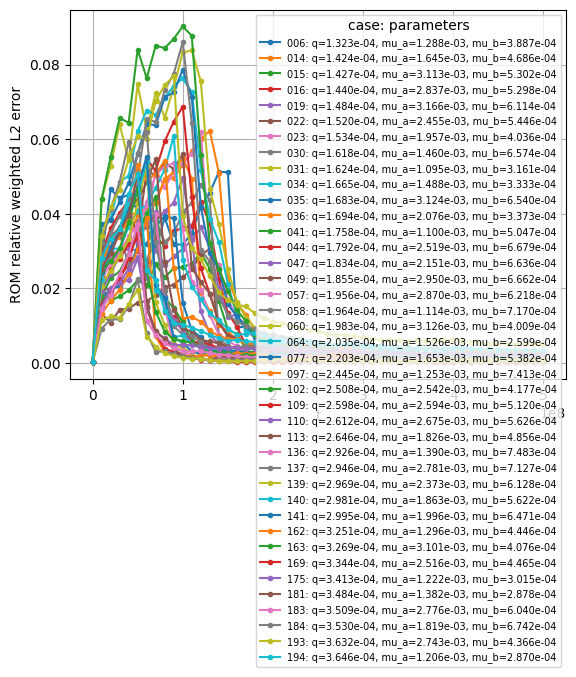

In [19]:
fig,ax=plt.subplots()
for case_id, trajectory in tm.groupby("case_id", sort=True):
    row=trajectory.iloc[0]
    label=f"{case_id:03d}: q={row.q_inj:.3e}, mu_a={row.mu_a:.3e}, mu_b={row.mu_b:.3e}"
    ax.plot(trajectory["t"],trajectory["ROM_relL2"],"o-",ms=3,label=label)
ax.set(xlabel="t",ylabel="ROM relative weighted L2 error")
ax.grid(); ax.legend(title="case: parameters",fontsize=7); plt.show()


## 12. POD error vs ROM error

If ROM error \(\approx\) POD error, regression is already good and POD truncation dominates.  
If ROM error \(\gg\) POD error, improve sampling/regression.  
If both are large, global linear POD is the bottleneck.

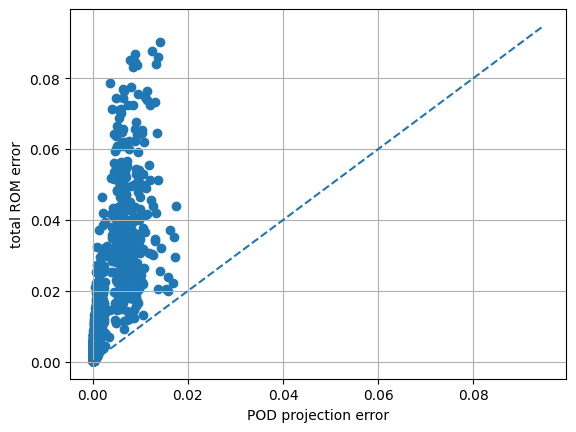

In [20]:
fig,ax=plt.subplots()
ax.scatter(poderr[test],romerr)
lims=[0,max(poderr[test].max(),romerr.max())*1.05]
ax.plot(lims,lims,"--")
ax.set(xlabel="POD projection error",ylabel="total ROM error")
ax.grid(); plt.show()

## 13. Per-coefficient diagnostics — decide whether to use one regressor per \(a_i\)

,mode,singular_value,cumulative_energy,R2_test,RMSE_test
0,1,5879.510723,0.837888,0.999714,1.236136
1,2,1903.509896,0.925712,0.998448,0.939993
2,3,1124.930495,0.956385,0.996140,0.871441
3,4,789.969278,0.971511,0.992830,0.830277
4,5,596.985508,0.980150,0.984528,0.921372
5,6,479.004768,0.985711,0.934191,1.527207
6,7,374.915614,0.989118,0.908809,1.411634
7,8,304.051475,0.991359,0.760710,1.908407
8,9,252.371500,0.992903,0.844585,1.258588
9,10,216.350748,0.994037,0.665176,1.652482


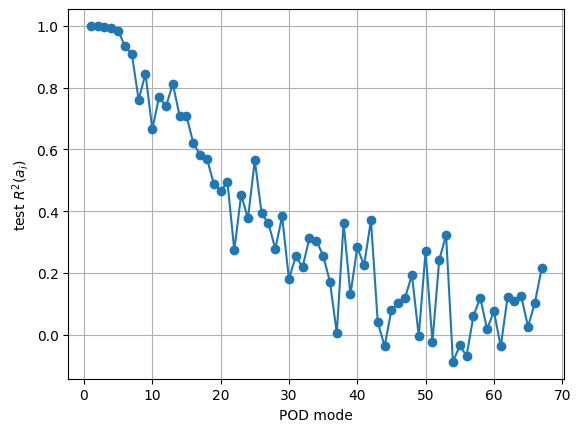

In [21]:
cm=[]
for j in range(r):
    cm.append(dict(
        mode=j+1,singular_value=svals[j],cumulative_energy=energy[j],
        R2_test=r2_score(At[:,j],Ahat[:,j]) if np.var(At[:,j])>0 else np.nan,
        RMSE_test=np.sqrt(np.mean((At[:,j]-Ahat[:,j])**2))))
cm=pd.DataFrame(cm)
display(cm.head(30))

fig,ax=plt.subplots()
ax.plot(cm["mode"],cm["R2_test"],"o-")
ax.set(xlabel="POD mode",ylabel=r"test $R^2(a_i)$"); ax.grid(); plt.show()

## 14. Optional spatial map for the worst unseen test snapshot

t=100000000.0, q=1.323279e-04, mu_a=1.287820e-03, mu_b=3.886964e-04, ROM relL2=3.1709e-02
Reading file /home/anderson/OpenFOAM/anderson-9/run/struct_impesFoam/impesFoam3ph_v6/impesFoam3ph/Examples/test/rom_5spot_qinj_mu/cases/q_006/constant/polyMesh/owner
Reading file /home/anderson/OpenFOAM/anderson-9/run/struct_impesFoam/impesFoam3ph_v6/impesFoam3ph/Examples/test/rom_5spot_qinj_mu/cases/q_006/constant/polyMesh/faces
Reading file /home/anderson/OpenFOAM/anderson-9/run/struct_impesFoam/impesFoam3ph_v6/impesFoam3ph/Examples/test/rom_5spot_qinj_mu/cases/q_006/constant/polyMesh/points
Reading file /home/anderson/OpenFOAM/anderson-9/run/struct_impesFoam/impesFoam3ph_v6/impesFoam3ph/Examples/test/rom_5spot_qinj_mu/cases/q_006/constant/polyMesh/neighbour


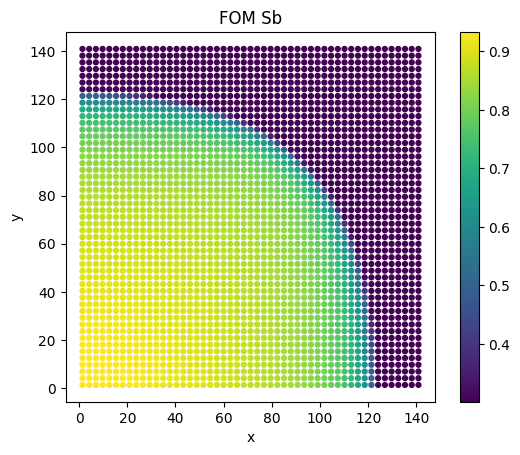

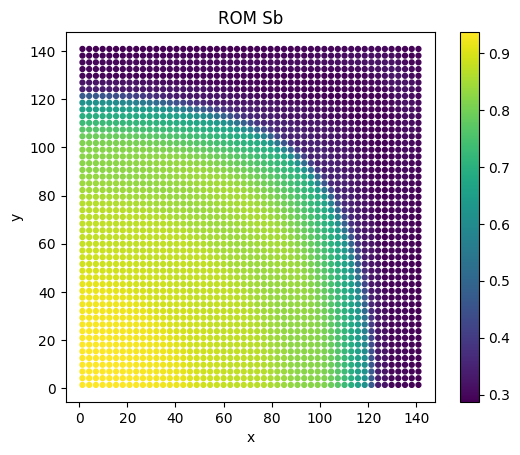

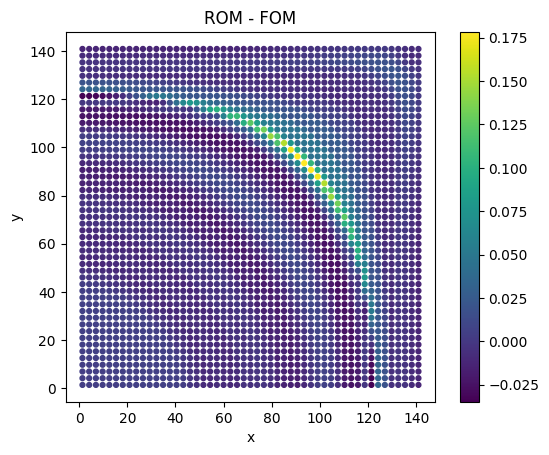

In [28]:
# iw=int(np.argmax(romerr))
iw = 10

utrue=X[test][iw]; urom=Xhat[iw]; ue=urom-utrue
row=tm.iloc[iw]
print(f"t={row.t}, q={row.q_inj:.6e}, mu_a={row.mu_a:.6e}, "
      f"mu_b={row.mu_b:.6e}, ROM relL2={row.ROM_relL2:.4e}")

case=CASES_DIR/f"q_{int(row.case_id):03d}"
try:
    mesh=fluidfoam.readmesh(str(case))
    x,y=np.asarray(mesh[0]).ravel(),np.asarray(mesh[1]).ravel()
    for vals,title in [(utrue,f"FOM {FIELD}"),(urom,f"ROM {FIELD}"),(ue,"ROM - FOM")]:
        fig,ax=plt.subplots()
        sc=ax.scatter(x,y,c=vals,s=12)
        ax.set_aspect("equal"); ax.set(xlabel="x",ylabel="y",title=title)
        plt.colorbar(sc,ax=ax); plt.show()
except Exception as e:
    print("Map skipped (fluidfoam readmesh API may differ):",e)

## 15. Online ROM prediction and approximate speed-up

In [23]:
def rom_predict(t_values,q,mu_a,mu_b):
    t_values=np.atleast_1d(np.asarray(t_values,dtype=float))
    if t_values.ndim != 1 or not np.all(np.isfinite(t_values)):
        raise ValueError("t_values must be a finite one-dimensional time array")
    for name, value in [("q_inj",q),("mu_a",mu_a),("mu_b",mu_b)]:
        if not np.isfinite(value) or value <= 0:
            raise ValueError(f"{name} must be finite and positive")
    df=pd.DataFrame({"t":t_values,
                     "q_inj":np.full(len(t_values),float(q)),
                     "mu_a":np.full(len(t_values),float(mu_a)),
                     "mu_b":np.full(len(t_values),float(mu_b))})
    Ah=unscale(best.predict(features(df)))
    return reconstruct(Ah),Ah

tic=time.perf_counter()
Unew,Anew=rom_predict(times,q0,mu_a0,mu_b0)
romtime=time.perf_counter()-tic
print(f"{len(times)} ROM fields in {romtime:.6f} s")
if "timings_df" in globals() and len(timings_df):
    print("mean FOM run:",timings_df.wall_time_s.mean(),"s")
    print("approx speed-up:",timings_df.wall_time_s.mean()/max(romtime,1e-12))

51 ROM fields in 4.869895 s


## 16. Save basis, normalization, regressor, and diagnostics

In [24]:
np.savez_compressed(ARTIFACTS_DIR/"pod_basis.npz",
    u_mean=u_mean,Phi=Phi,V=V,singular_values=svals,energy=energy,
    q0=q0,mu_a0=mu_a0,mu_b0=mu_b0,
    feature_names=np.asarray(["t", "q_inj", "mu_a", "mu_b"]),
    parameter_factor_bounds=np.asarray([
        [Q_FACTOR_MIN,Q_FACTOR_MAX],
        [MU_A_FACTOR_MIN,MU_A_FACTOR_MAX],
        [MU_B_FACTOR_MIN,MU_B_FACTOR_MAX]]),
    t_min=tmin,t_max=tmax,A_mean=Amean,A_std=Astd)
joblib.dump(best,ARTIFACTS_DIR/"regressor.joblib")
sampling_df.to_csv(ARTIFACTS_DIR/"parameter_sampling.csv",index=False)
results.to_csv(ARTIFACTS_DIR/"model_comparison.csv",index=False)
tm.to_csv(ARTIFACTS_DIR/"test_errors.csv",index=False)
cm.to_csv(ARTIFACTS_DIR/"coefficient_metrics.csv",index=False)
print("Saved to",ARTIFACTS_DIR)

Saved to /home/anderson/OpenFOAM/anderson-9/run/struct_impesFoam/impesFoam3ph_v6/impesFoam3ph/Examples/test/rom_5spot_qinj_mu/artifacts


# What to inspect first

1. Singular-value decay and selected \(r\).
2. POD projection error on **test** $(q_{\rm inj},\mu_a,\mu_b)$ combinations.
3. Validation ranking of regressors.
4. Total ROM error on held-out $(q_{\rm inj},\mu_a,\mu_b)$ combinations.
5. \(R^2\) of each \(a_i\).
6. Predicted saturation range (`Sb_min_pred`, `Sb_max_pred`).
7. Speed-up.

Recommended next study: increase `N_CASES` and plot ROM test error versus the number of training $(q_{\rm inj},\mu_a,\mu_b)$ combinations. Then tune each regressor per POD coefficient.